# XGBoost — Hyperparameter Tuning

Loads the shared train/val/test splits saved by `data_eda.ipynb`, vectorizes with TF-IDF (update the
config below if `bow_vs_tfidf.ipynb` found a better one than the default), then grid-searches
XGBoost's key hyperparameters. Every candidate combination is logged to MLflow, and the best model
gets registered.

Run `data_eda.ipynb` first — this notebook depends on the CSVs it saves.

In [1]:
# ── libraries ──
import os
import time
import pickle

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
import xgboost as xgb
from xgboost import XGBClassifier

import mlflow
import mlflow.xgboost
from mlflow.tracking import MlflowClient

/Users/vijay/Desktop/sentiment-drl-trading/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# ── config + load the shared splits ──
MODEL_NAME = "XGBoost"
SEED = 42

DATA_DIR = "../data/processed"
RESULTS_DIR = "results"
MODELS_DIR = "saved_models"
os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(MODELS_DIR, exist_ok=True)

MLFLOW_EXPERIMENT = "IndianFinSentiment_ClassicalML"
mlflow.set_tracking_uri("sqlite:///mlflow.db")
mlflow.set_experiment(MLFLOW_EXPERIMENT)

train_df = pd.read_csv(f"{DATA_DIR}/train.csv")
val_df = pd.read_csv(f"{DATA_DIR}/val.csv")
test_df = pd.read_csv(f"{DATA_DIR}/test.csv")
print(f"Train: {len(train_df)}  |  Val: {len(val_df)}  |  Test: {len(test_df)}")

Train: 7094  |  Val: 946  |  Test: 1419


## Vectorize with TF-IDF

**Update these two values** if `bow_vs_tfidf.ipynb` found a better config than this default.

In [3]:
TFIDF_MAX_FEATURES = 15_000
TFIDF_NGRAM_RANGE = (1, 2)

vectorizer = TfidfVectorizer(max_features=TFIDF_MAX_FEATURES, ngram_range=TFIDF_NGRAM_RANGE, min_df=2)
X_train = vectorizer.fit_transform(train_df["text"])
X_val = vectorizer.transform(val_df["text"])
X_test = vectorizer.transform(test_df["text"])

y_train, y_val, y_test = train_df["label_id"], val_df["label_id"], test_df["label_id"]
print(f"TF-IDF matrix shape: {X_train.shape}")

TF-IDF matrix shape: (7094, 11720)


In [4]:
def evaluate(y_true, y_pred):
    per_class = f1_score(y_true, y_pred, average=None, labels=[0, 1, 2])
    return {
        "accuracy": round(accuracy_score(y_true, y_pred), 4),
        "f1_weighted": round(f1_score(y_true, y_pred, average="weighted"), 4),
        "f1_positive": round(per_class[0], 4),
        "f1_neutral": round(per_class[1], 4),
        "f1_negative": round(per_class[2], 4),
    }


def plot_confusion_matrix(y_true, y_pred, name):
    cm = confusion_matrix(y_true, y_pred)
    cm_pct = cm.astype(float) / cm.sum(axis=1)[:, None]
    fig, ax = plt.subplots(figsize=(5, 4))
    sns.heatmap(cm_pct, annot=True, fmt=".1%", cmap="Blues",
                xticklabels=["positive", "neutral", "negative"],
                yticklabels=["positive", "neutral", "negative"], ax=ax)
    ax.set_title(f"Confusion Matrix - {name}")
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
    path = f"{RESULTS_DIR}/cm_{name.lower().replace(' ', '_')}.png"
    plt.savefig(path, dpi=120, bbox_inches="tight")
    plt.show()
    return path

## Broader hyperparameter search (structural params, fixed n_estimators)

The old version only searched `n_estimators` (2) x `max_depth` (3) x `learning_rate` (2) — 12
candidates x 3-fold CV = 36 fits. This version searches `max_depth`, `learning_rate`, `subsample`,
`colsample_bytree`, `min_child_weight`, `reg_alpha`, and `reg_lambda`, with `n_estimators` fixed
at a moderate 300 for this phase, `RandomizedSearchCV` (n_iter=30, cv=3), and `verbose=2`.

(Unlike LightGBM/sklearn, `XGBClassifier` doesn't take a `class_weight` constructor argument —
class balancing there works via per-sample weights passed at `.fit()` time, which doesn't fit
cleanly into a `RandomizedSearchCV` grid, so it's left out of this search rather than faked.)

Same reasoning as LightGBM: `n_estimators` isn't part of this search because the next section
tunes it directly and far more precisely via XGBoost's native early stopping, which watches
validation loss every boosting round instead of guessing at a few fixed values.

In [5]:
model = XGBClassifier(n_estimators=300, random_state=SEED, n_jobs=-1, verbosity=0, eval_metric="mlogloss")

param_distributions = {
    "max_depth": [3, 4, 6, 8, 10],
    "learning_rate": [0.01, 0.03, 0.05, 0.1, 0.2],
    "subsample": [0.6, 0.8, 1.0],
    "colsample_bytree": [0.6, 0.8, 1.0],
    "min_child_weight": [1, 3, 5],
    "reg_alpha": [0.0, 0.1, 1.0],
    "reg_lambda": [0.0, 0.1, 1.0],
}

start = time.time()
random_search = RandomizedSearchCV(
    model, param_distributions, n_iter=30, cv=3, scoring="f1_weighted",
    n_jobs=-1, random_state=SEED, verbose=2,
)
random_search.fit(X_train, y_train)
search_time = time.time() - start

n_combos = len(random_search.cv_results_["params"])
print(f"\nRandom search done in {search_time:.1f}s — tried {n_combos} combinations x 3-fold CV = {n_combos * 3} fits")
print(f"Best params: {random_search.best_params_}")
print(f"Best CV F1 (weighted): {random_search.best_score_:.4f}")

Fitting 3 folds for each of 30 candidates, totalling 90 fits



Random search done in 873.3s — tried 30 combinations x 3-fold CV = 90 fits
Best params: {'subsample': 0.6, 'reg_lambda': 0.1, 'reg_alpha': 0.1, 'min_child_weight': 1, 'max_depth': 10, 'learning_rate': 0.05, 'colsample_bytree': 0.8}
Best CV F1 (weighted): 0.7827


## Log every candidate combination to MLflow

In [6]:
for params, mean_score, std_score in zip(
    random_search.cv_results_["params"],
    random_search.cv_results_["mean_test_score"],
    random_search.cv_results_["std_test_score"],
):
    run_name = f"{MODEL_NAME}_" + "_".join(f"{k}={v}" for k, v in params.items())
    with mlflow.start_run(run_name=run_name):
        mlflow.log_params(params)
        mlflow.log_metric("cv_f1_weighted_mean", round(float(mean_score), 4))
        mlflow.log_metric("cv_f1_weighted_std", round(float(std_score), 4))

print(f"Logged {len(random_search.cv_results_['params'])} candidate runs to MLflow.")

Logged 30 candidate runs to MLflow.


## Overfitting check: train vs val vs test (CV-best structural params, fixed 300 trees)

In [7]:
cv_best_model = random_search.best_estimator_
train_metrics_cv = evaluate(y_train, cv_best_model.predict(X_train))
val_metrics_cv = evaluate(y_val, cv_best_model.predict(X_val))
test_metrics_cv = evaluate(y_test, cv_best_model.predict(X_test))

print(f"{'Split':<8} {'Accuracy':>10} {'F1 (weighted)':>14}")
for name, m in [("Train", train_metrics_cv), ("Val", val_metrics_cv), ("Test", test_metrics_cv)]:
    print(f"{name:<8} {m['accuracy']:>10.4f} {m['f1_weighted']:>14.4f}")

gap = train_metrics_cv["f1_weighted"] - val_metrics_cv["f1_weighted"]
print(f"\nTrain-Val F1 gap: {gap:.4f} (large positive gap = overfitting)")

Split      Accuracy  F1 (weighted)
Train        0.9091         0.9093
Val          0.7939         0.7940
Test         0.7851         0.7853

Train-Val F1 gap: 0.1153 (large positive gap = overfitting)


## Real epochs + early stopping: native boosting-round early stopping

Same idea as LightGBM — retrain the winning structural config with a high round ceiling (2,000)
and `early_stopping_rounds=30` watching validation `mlogloss`. A custom `TrainingCallback` prints
**train accuracy, train F1, val accuracy, val F1, test accuracy, and test F1 every 10 rounds** —
not just the internal loss value — so the training is fully visible. Early stopping itself still
only watches validation loss; the test numbers are printed purely for visibility.

In [8]:
best_struct_params = random_search.best_params_


class MetricsCallback(xgb.callback.TrainingCallback):
    """Prints train/val/test accuracy AND F1 every `period` boosting rounds — early stopping
    itself still watches validation mlogloss only; this callback is purely for visibility."""
    def __init__(self, period=10):
        self.period = period

    def after_iteration(self, model, epoch, evals_log):
        n_iter = epoch + 1
        if n_iter % self.period == 0 or epoch == 0:
            tr_proba = model.predict(xgb.DMatrix(X_train), iteration_range=(0, n_iter))
            va_proba = model.predict(xgb.DMatrix(X_val), iteration_range=(0, n_iter))
            te_proba = model.predict(xgb.DMatrix(X_test), iteration_range=(0, n_iter))
            tr_pred, va_pred, te_pred = np.argmax(tr_proba, axis=1), np.argmax(va_proba, axis=1), np.argmax(te_proba, axis=1)
            tr_acc, tr_f1 = accuracy_score(y_train, tr_pred), f1_score(y_train, tr_pred, average="weighted")
            va_acc, va_f1 = accuracy_score(y_val, va_pred), f1_score(y_val, va_pred, average="weighted")
            te_acc, te_f1 = accuracy_score(y_test, te_pred), f1_score(y_test, te_pred, average="weighted")
            print(f"Epoch {n_iter:>4} | train_acc={tr_acc:.4f} train_f1={tr_f1:.4f} | "
                  f"val_acc={va_acc:.4f} val_f1={va_f1:.4f} | test_acc={te_acc:.4f} test_f1={te_f1:.4f}")
        return False


es_model = XGBClassifier(
    n_estimators=2000, random_state=SEED, n_jobs=-1, verbosity=0,
    eval_metric="mlogloss", early_stopping_rounds=30, callbacks=[MetricsCallback(period=10)],
    **best_struct_params,
)
es_model.fit(X_train, y_train, eval_set=[(X_val, y_val)], verbose=False)

print(f"\nStopped at best_iteration={es_model.best_iteration}")

es_test_metrics = evaluate(y_test, es_model.predict(X_test))
es_val_metrics = evaluate(y_val, es_model.predict(X_val))
es_train_metrics = evaluate(y_train, es_model.predict(X_train))
print(f"\n{'Split':<8} {'Accuracy':>10} {'F1 (weighted)':>14}")
for name, m in [("Train", es_train_metrics), ("Val", es_val_metrics), ("Test", es_test_metrics)]:
    print(f"{name:<8} {m['accuracy']:>10.4f} {m['f1_weighted']:>14.4f}")

Epoch    1 | train_acc=0.5165 train_f1=0.4233 | val_acc=0.4863 val_f1=0.3953 | test_acc=0.5088 test_f1=0.4160


Epoch   10 | train_acc=0.7134 train_f1=0.7086 | val_acc=0.7008 val_f1=0.6960 | test_acc=0.6779 test_f1=0.6707


Epoch   20 | train_acc=0.7333 train_f1=0.7308 | val_acc=0.7125 val_f1=0.7094 | test_acc=0.6956 test_f1=0.6915


Epoch   30 | train_acc=0.7418 train_f1=0.7400 | val_acc=0.7146 val_f1=0.7123 | test_acc=0.7026 test_f1=0.6998


Epoch   40 | train_acc=0.7628 train_f1=0.7620 | val_acc=0.7241 val_f1=0.7235 | test_acc=0.7125 test_f1=0.7096


...

Epoch  630 | train_acc=0.9602 train_f1=0.9603 | val_acc=0.8087 val_f1=0.8088 | test_acc=0.7921 test_f1=0.7924


Epoch  640 | train_acc=0.9612 train_f1=0.9613 | val_acc=0.8087 val_f1=0.8088 | test_acc=0.7914 test_f1=0.7918


Epoch  650 | train_acc=0.9612 train_f1=0.9613 | val_acc=0.8097 val_f1=0.8099 | test_acc=0.7935 test_f1=0.7938


Epoch  660 | train_acc=0.9632 train_f1=0.9633 | val_acc=0.8087 val_f1=0.8088 | test_acc=0.7893 test_f1=0.7896

Stopped at best_iteration=631



Split      Accuracy  F1 (weighted)
Train        0.9607         0.9607
Val          0.8087         0.8088
Test         0.7928         0.7931


In [9]:
# ── the early-stopped model (best hyperparameters, trained epoch-by-epoch — each boosting round
# is an epoch — with early stopping) is the final model — always. CV-best (fixed 300 trees,
# one-shot) is kept as an informational reference point only. ──
print(f"{'Model':<32} {'F1 (weighted)':>14} {'Accuracy':>10}")
print("-" * 58)
print(f"{'CV-best (300 trees, one-shot)':<32} {test_metrics_cv['f1_weighted']:>14.4f} {test_metrics_cv['accuracy']:>10.4f}")
print(f"{'Early-stopped (' + str(es_model.best_iteration) + ' trees)':<32} {es_test_metrics['f1_weighted']:>14.4f} {es_test_metrics['accuracy']:>10.4f}")

final_model, final_variant, final_test_metrics = es_model, f"EarlyStopped_{es_model.best_iteration}trees", es_test_metrics
print(f"\nFinal model (epoch-trained, best hyperparameters): {MODEL_NAME} ({final_variant})")

Model                             F1 (weighted)   Accuracy
----------------------------------------------------------
CV-best (300 trees, one-shot)            0.7853     0.7851
Early-stopped (631 trees)                0.7931     0.7928

Final model (epoch-trained, best hyperparameters): XGBoost (EarlyStopped_631trees)


## Evaluate the best model on the held-out test set

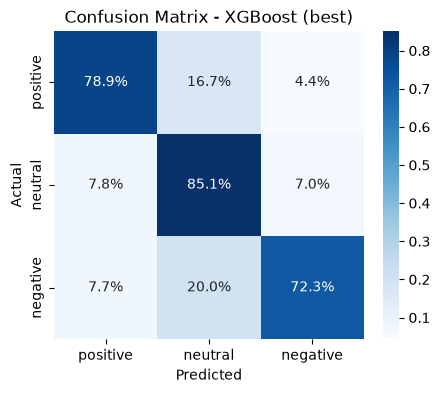

2026/07/19 17:11:47 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.



XGBoost (EarlyStopped_631trees) — TEST RESULTS
              precision    recall  f1-score   support

    positive       0.85      0.79      0.82       503
     neutral       0.72      0.85      0.78       511
    negative       0.83      0.72      0.78       405

    accuracy                           0.79      1419
   macro avg       0.80      0.79      0.79      1419
weighted avg       0.80      0.79      0.79      1419



In [10]:
test_preds = final_model.predict(X_test)
test_metrics = evaluate(y_test, test_preds)

with mlflow.start_run(run_name=f"{MODEL_NAME}_BEST_{final_variant}"):
    mlflow.log_params({"variant": final_variant, **best_struct_params})
    mlflow.log_param("n_estimators", getattr(final_model, "best_iteration", None) or final_model.n_estimators)
    mlflow.log_param("tfidf_max_features", TFIDF_MAX_FEATURES)
    mlflow.log_param("tfidf_ngram_range", str(TFIDF_NGRAM_RANGE))
    mlflow.log_metrics(test_metrics)
    mlflow.log_metric("search_time_seconds", round(search_time, 2))

    cm_path = plot_confusion_matrix(y_test, test_preds, f"{MODEL_NAME} (best)")
    mlflow.log_artifact(cm_path)
    mlflow.xgboost.log_model(final_model, "model")
    run_id = mlflow.active_run().info.run_id

print(f"\n{MODEL_NAME} ({final_variant}) — TEST RESULTS")
print(classification_report(y_test, test_preds, target_names=["positive", "neutral", "negative"]))

with open(f"{MODELS_DIR}/{MODEL_NAME.lower()}_best.pkl", "wb") as f:
    pickle.dump({"vectorizer": vectorizer, "model": final_model, "variant": final_variant}, f)

## Register the best model in the MLflow Model Registry

In [11]:
client = MlflowClient()
try:
    registered = mlflow.register_model(model_uri=f"runs:/{run_id}/model", name=f"{MODEL_NAME}_Classifier")
    print(f"Registered '{MODEL_NAME}_Classifier' version {registered.version}")
except Exception as e:
    print(f"Registration skipped/failed: {e}")

print(f"\nBest {MODEL_NAME} test F1 (weighted): {test_metrics['f1_weighted']:.4f}")

Registered model 'XGBoost_Classifier' already exists. Creating a new version of this model...
2026/07/19 17:11:52 WARNING mlflow.tracking._model_registry.fluent: Run with id e42263174c154e9482f0db8c6ed9d573 has no artifacts at artifact path 'model', registering model based on models:/m-2a4e09aa0ab04965ab604987d204d98b instead


Registered 'XGBoost_Classifier' version 2

Best XGBoost test F1 (weighted): 0.7931


Created version '2' of model 'XGBoost_Classifier'.
